## Mechanical Changes

- **Narrower Stance:** Reduced the distance between his feet from approximately 31.5 inches to 18–19 inches.
- **Box Positioning:** Moved closer to the plate and deeper into the batter's box, adopting a more upright stance with less torso hunch.
- **Hand Position & Bat Angle:** Lowered his hands from shoulder level to below the chest, near his belt, while raising the bat to a more upright angle. This created a shorter, more direct path to the ball.
- **Stride & Leg Kick:** Reintroduced a more deliberate stride and leg kick, which became more pronounced into June, while maintaining balance and avoiding lunging forward.

## Mental & Approach Shifts

- **Selective Aggression:** Became more selective at the plate rather than swinging at every pitch.
- **Pitch Hunting:** Focused on identifying and attacking specific pitches and locations rather than expanding his swing zone. This coincided with his walk rate nearly doubling from 4.5% in the previous season to 8.5%.

In [ ]:
%pip install numpy pandas matplotlib pybaseball

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pybaseball import statcast_batter, cache
import calendar

In [ ]:
cache.enable()

PCA_ID = 691718
df = statcast_batter("2026-03-20", "2026-10-05", PCA_ID)
df = df[df["game_type"] == "R"].copy()   # regular season only
df["game_date"] = pd.to_datetime(df["game_date"])
df["month"] = df["game_date"].dt.month.clip(lower=4)  # fold late March into April

print(len(df), "pitches from", df["game_date"].min().date(), "to", df["game_date"].max().date()) # Should be around ~2300-2500

2922 pitches from 2026-03-26 to 2026-09-27


In [58]:
# All possible swing outcomes
SWINGS = [
    "swinging_strike",
    "swinging_strike_blocked",
    "foul",
    "foul_tip",
    "hit_into_play",
    "foul_bunt",
    "missed_bunt"
]

# All possible swing and miss outcomes (subset of above)
WHIFFS = [
    "swinging_strike",
    "swinging_strike_blocked",
    "missed_bunt"
]

# Returns a boolean for each row
df["swing"] = df["description"].isin(SWINGS)
df["whiff"] = df["description"].isin(WHIFFS)

def balls_in_play(d):
    return d[(d["type"] == "X") & d["launch_speed"].notna()]

def summarize(month_data):
    pa = month_data[month_data["woba_denom"] == 1]
    xwoba = pa["estimated_woba_using_speedangle"].fillna(pa["woba_value"])
    out_of_zone = month_data[month_data["zone"] >= 11]
    bip = balls_in_play(month_data)

    return pd.Series({
        "PA": len(pa),
        "wOBA": pa["woba_value"].mean(),
        "xwOBA": xwoba.mean(),
        "chase_rate": out_of_zone["swing"].mean(),
        "whiff_rate": month_data["whiff"].sum() / month_data["swing"].sum(),
        "BIP": len(bip),
        "avg_EV": bip["launch_speed"].mean(),
        "barrel_rate": (bip["launch_speed_angle"] == 6).mean(),
    })

monthly = df.groupby("month").apply(summarize).round(3)
monthly.index = [calendar.month_abbr[m] for m in monthly.index]
monthly

/tmp/ipykernel_9846/797973386.py:43: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  monthly = df.groupby("month").apply(summarize).round(3)


,PA,wOBA,xwOBA,chase_rate,whiff_rate,BIP,avg_EV,barrel_rate
Apr,126.0,0.296,0.286,0.458,0.277,79.0,88.185,0.076
May,122.0,0.342,0.404,0.307,0.214,78.0,91.545,0.128
Jun,123.0,0.513,0.399,0.334,0.291,73.0,88.077,0.123
Jul,108.0,0.427,0.361,0.272,0.239,59.0,87.749,0.153
Aug,131.0,0.440,0.396,0.332,0.201,85.0,90.242,0.176
Sep,107.0,0.380,0.400,0.351,0.228,69.0,92.858,0.145


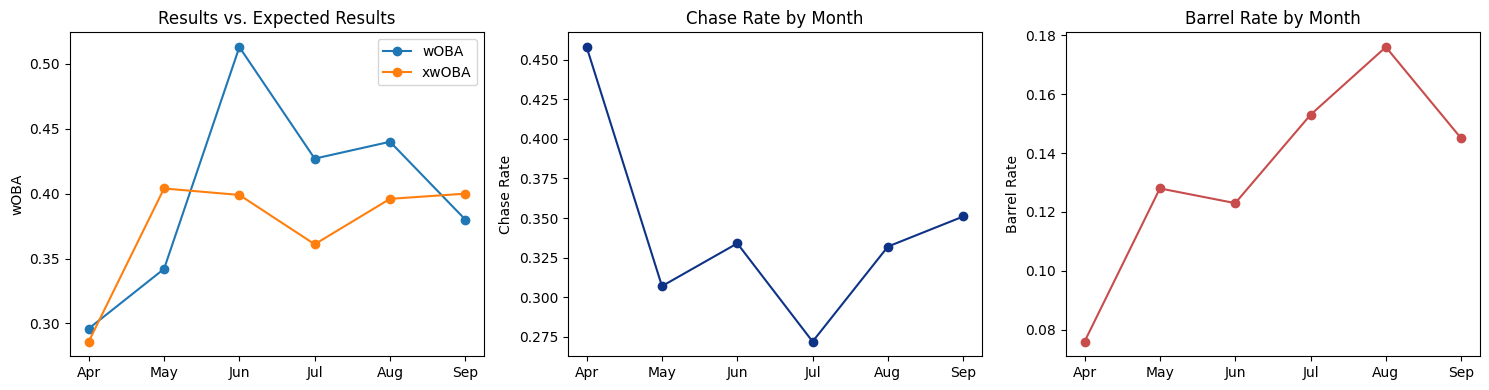

In [59]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

monthly[["wOBA", "xwOBA"]].plot(ax=axes[0], marker="o")
axes[0].set_title("Results vs. Expected Results")
axes[0].set_ylabel("wOBA")

monthly["chase_rate"].plot(ax=axes[1], marker="o", color="#0e3386")
axes[1].set_title("Chase Rate by Month")
axes[1].set_ylabel("Chase Rate")

monthly["barrel_rate"].plot(ax=axes[2], marker="o", color="#c84c4c")
axes[2].set_title("Barrel Rate by Month")
axes[2].set_ylabel("Barrel Rate")

plt.tight_layout()
plt.savefig("pca-2026.png", dpi=200)
plt.show()

In [53]:
def balls_in_play(d):
    return d[(d["type"] == "X") & d["launch_speed"].notna()]

turnaround = "2026-05-14"

before = df[df["game_date"] < turnaround]
after = df[df["game_date"] >= turnaround]

for name, data in [("Before", before), ("After", after)]:
    out_of_zone = data[data["zone"] >= 11]

    print(name)
    print("Swing rate:", round(data["swing"].mean(), 3))
    print("Chase rate:", round(out_of_zone["swing"].mean(), 3))
    print("Whiff rate:", round(data["whiff"].sum() / data["swing"].sum(), 3))
    print()

for name, data in [("Before", before), ("After", after)]:
    bip = balls_in_play(data)
    barrels = (bip["launch_speed_angle"] == 6).sum()

    print(name)
    print("Balls in play:", len(bip))
    print("Average exit velocity:", round(bip["launch_speed"].mean(), 2))
    print("Barrels:", barrels)
    print("Barrel rate:", round(barrels / len(bip), 3))
    print("Hard-hit rate (95+ mph):", round((bip["launch_speed"] >= 95).mean(), 3))
    print()

Before
Swing rate: 0.548
Chase rate: 0.424
Whiff rate: 0.254

After
Swing rate: 0.482
Chase rate: 0.319
Whiff rate: 0.238

Before
Balls in play: 113
Average exit velocity: 88.88
Barrels: 9
Barrel rate: 0.08
Hard-hit rate (95+ mph): 0.469

After
Balls in play: 330
Average exit velocity: 90.15
Barrels: 50
Barrel rate: 0.152
Hard-hit rate (95+ mph): 0.494



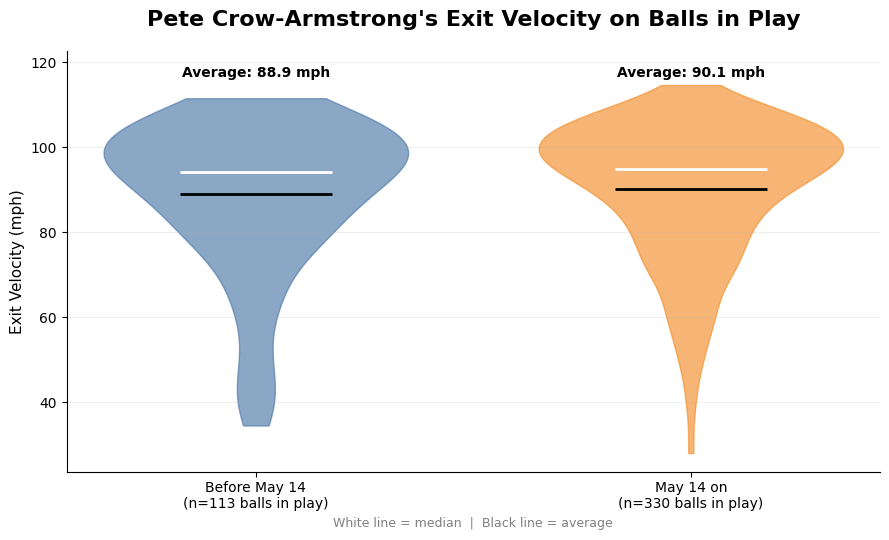

In [57]:
before_ev = balls_in_play(before)["launch_speed"]
after_ev = balls_in_play(after)["launch_speed"]

fig, ax = plt.subplots(figsize=(9, 5.5))

# Create the violin plots
parts = ax.violinplot(
    [before_ev, after_ev],
    positions=[1, 2],
    widths=0.7,
    showmeans=True,
    showmedians=True,
    showextrema=False
)

# Give each period its own color
colors = ["#4C78A8", "#F28E2B"]

for body, color in zip(parts["bodies"], colors):
    body.set_facecolor(color)
    body.set_edgecolor(color)
    body.set_alpha(0.65)

# Style the average and median markers
parts["cmeans"].set_color("black")
parts["cmeans"].set_linewidth(2)

parts["cmedians"].set_color("white")
parts["cmedians"].set_linewidth(2)

# Add average exit velocity labels above both violins at the same height
label_y = max(before_ev.max(), after_ev.max()) + 2
ax.set_ylim(top=label_y + 6)

for x, data in zip([1, 2], [before_ev, after_ev]):
    ax.text(
        x, label_y,
        f"Average: {data.mean():.1f} mph",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xticks([1, 2])
ax.set_xticklabels([
    f"Before May 14\n(n={len(before_ev)} balls in play)",
    f"May 14 on\n(n={len(after_ev)} balls in play)"
])

ax.set_title(
    "Pete Crow-Armstrong's Exit Velocity on Balls in Play",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_ylabel("Exit Velocity (mph)", fontsize=11)
ax.set_xlabel("White line = median  |  Black line = average", fontsize=9, color="gray")

ax.grid(axis="y", alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("Fig2.png", dpi=200, bbox_inches="tight")
plt.show()

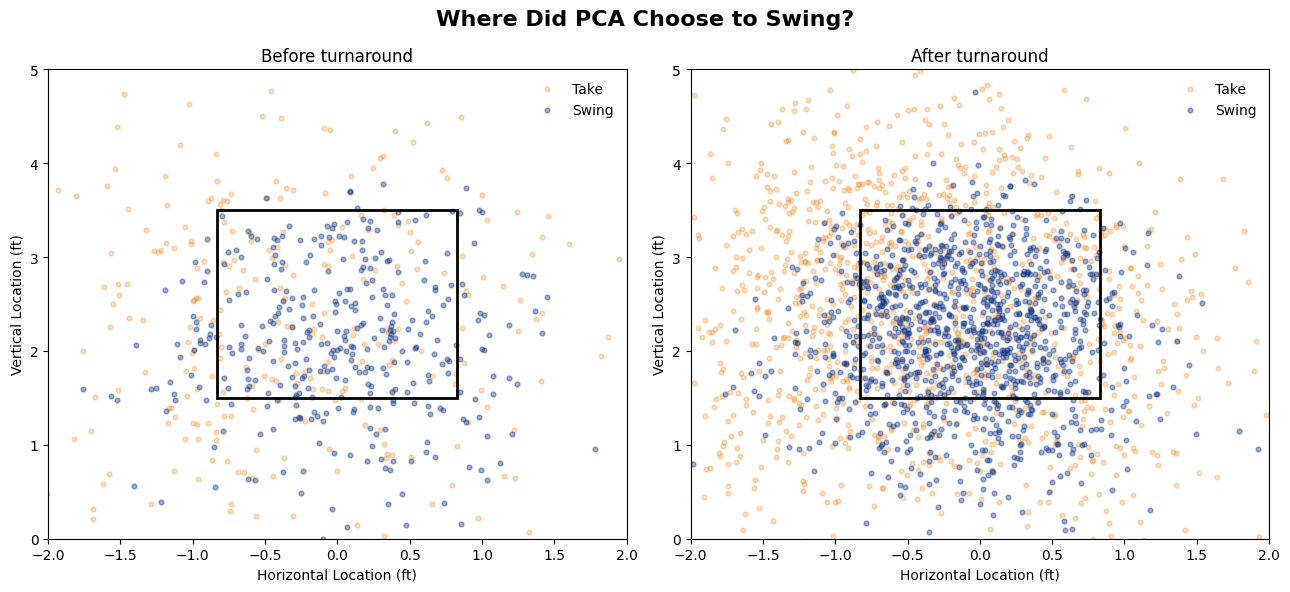

In [51]:
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

periods = [
    ("Before turnaround", before),
    ("After turnaround", after)
]

for ax, (title, data) in zip(axes, periods):

    # Plot pitches he took
    taken = data[data["swing"] == False]
    ax.scatter(
        taken["plate_x"],
        taken["plate_z"],
        color="#F28E2B",
        alpha=0.3,
        s=12,
        label="Take"
    )

    # Plot pitches he swung at
    swung = data[data["swing"] == True]
    ax.scatter(
        swung["plate_x"],
        swung["plate_z"],
        color="#0E3386",
        alpha=0.4,
        s=12,
        label="Swing"
    )

    # Add approximate strike zone
    zone = Rectangle(
        (-0.83, 1.5),
        1.66,
        2,
        fill=False,
        edgecolor="black",
        linewidth=2
    )

    ax.add_patch(zone)

    ax.set_xlim(-2, 2)
    ax.set_ylim(0, 5)
    ax.set_title(title)
    ax.set_xlabel("Horizontal Location (ft)")
    ax.set_ylabel("Vertical Location (ft)")
    ax.legend(frameon=False)

fig.suptitle(
    "Where Did PCA Choose to Swing?",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [50]:
results = []

for name, data in periods:

    in_zone = data[data["zone"].between(1, 9)]
    out_zone = data[data["zone"].between(11, 14)]

    total_swings = data["swing"].sum()

    results.append({
        "Period": name,
        "Pitches": len(data),
        "Swings": int(total_swings),
        "Swing Rate (%)": data["swing"].mean() * 100,
        "In-Zone Swing Rate (%)": in_zone["swing"].mean() * 100,
        "Chase Rate (%)": out_zone["swing"].mean() * 100,
        "Swings Inside Zone (%)": (
            in_zone["swing"].sum() / total_swings * 100
            if total_swings > 0 else 0
        )
    })

swing_comparison = pd.DataFrame(results).set_index("Period")

swing_comparison.round(1)

,Pitches,Swings,Swing Rate (%),In-Zone Swing Rate (%),Chase Rate (%),Swings Inside Zone (%)
Period,,,,,,
Before turnaround,641,351,54.8,70.3,42.4,58.1
After turnaround,2281,1099,48.2,68.1,31.9,64.6


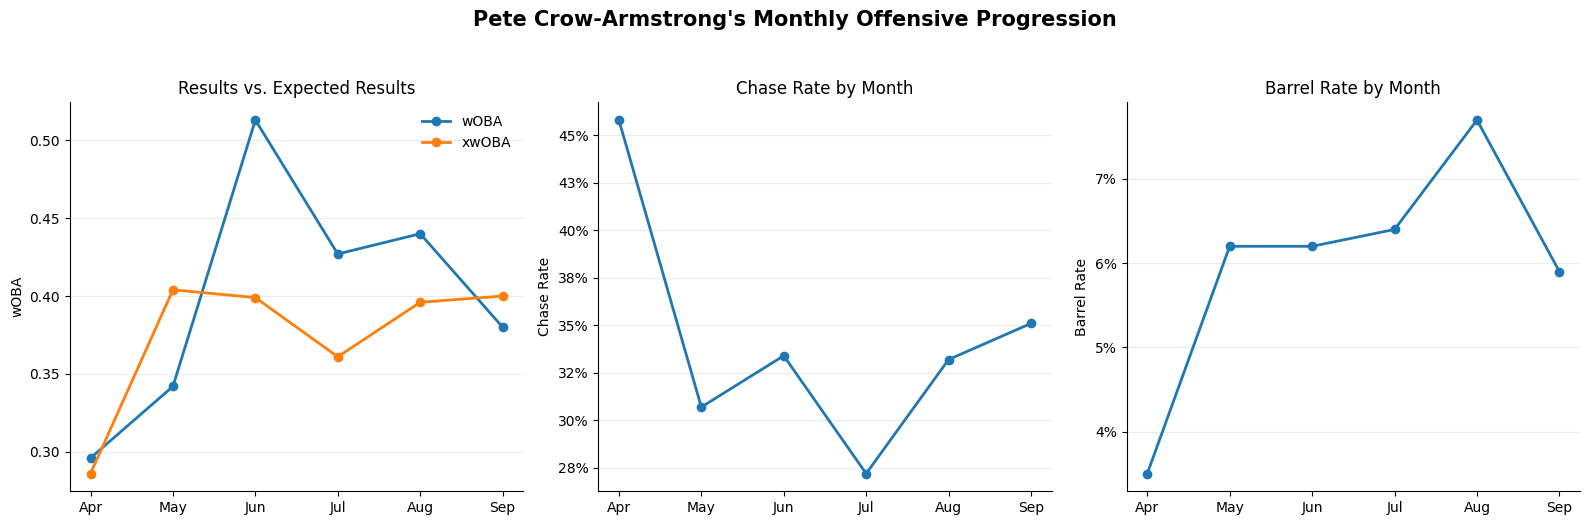

In [52]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Monthly data
monthly = pd.DataFrame({
    "month": ["Apr", "May", "Jun", "Jul", "Aug", "Sep"],
    "wOBA": [0.296, 0.342, 0.513, 0.427, 0.440, 0.380],
    "xwOBA": [0.286, 0.404, 0.399, 0.361, 0.396, 0.400],
    "chase_rate": [0.458, 0.307, 0.334, 0.272, 0.332, 0.351],
    "barrel_rate": [0.035, 0.062, 0.062, 0.064, 0.077, 0.059]
})

# Create three side-by-side plots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. wOBA vs. xwOBA
axes[0].plot(monthly["month"], monthly["wOBA"],
             marker="o", linewidth=2, label="wOBA")

axes[0].plot(monthly["month"], monthly["xwOBA"],
             marker="o", linewidth=2, label="xwOBA")

axes[0].set_title("Results vs. Expected Results")
axes[0].set_ylabel("wOBA")
axes[0].legend(frameon=False)

# 2. Chase Rate
axes[1].plot(monthly["month"], monthly["chase_rate"],
             marker="o", linewidth=2)

axes[1].set_title("Chase Rate by Month")
axes[1].set_ylabel("Chase Rate")
axes[1].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

# 3. Barrel Rate
axes[2].plot(monthly["month"], monthly["barrel_rate"],
             marker="o", linewidth=2)

axes[2].set_title("Barrel Rate by Month")
axes[2].set_ylabel("Barrel Rate")
axes[2].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

# Formatting
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)

fig.suptitle(
    "Pete Crow-Armstrong's Monthly Offensive Progression",
    fontsize=15,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()